In [1]:

import zipfile
import os

zip_path = "/content/eda starbucks.zip"
extract_path = "/content/Starbucks_Dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print(os.listdir(extract_path))


Dataset extracted successfully!
['Untitled0 (1).ipynb', 'archive']


In [2]:

import pandas as pd
import glob
import os

# Find the extracted CSV file
csv_path = glob.glob(
    "/content/Starbucks_Dataset/**/*.csv",
    recursive=True
)[0]

# Load the dataset
df = pd.read_csv(csv_path)

# Display dataset information
print("STARBUCKS DATASET LOADED SUCCESSFULLY!")
print("\nDataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()


STARBUCKS DATASET LOADED SUCCESSFULLY!

Dataset Shape: (242, 18)

Column Names:
['Beverage_category', 'Beverage', 'Beverage_prep', 'Calories', ' Total Fat (g)', 'Trans Fat (g) ', 'Saturated Fat (g)', ' Sodium (mg)', ' Total Carbohydrates (g) ', 'Cholesterol (mg)', ' Dietary Fibre (g)', ' Sugars (g)', ' Protein (g) ', 'Vitamin A (% DV) ', 'Vitamin C (% DV)', ' Calcium (% DV) ', 'Iron (% DV) ', 'Caffeine (mg)']

First 5 Records:


,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Beverage_category          242 non-null    object 
 1   Beverage                   242 non-null    object 
 2   Beverage_prep              242 non-null    object 
 3   Calories                   242 non-null    int64  
 4    Total Fat (g)             242 non-null    object 
 5   Trans Fat (g)              242 non-null    float64
 6   Saturated Fat (g)          242 non-null    float64
 7    Sodium (mg)               242 non-null    int64  
 8    Total Carbohydrates (g)   242 non-null    int64  
 9   Cholesterol (mg)           242 non-null    int64  
 10   Dietary Fibre (g)         242 non-null    int64  
 11   Sugars (g)                242 non-null    int64  
 12   Protein (g)               242 non-null    float64
 13  Vitamin A (% DV)           2

In [3]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())


Missing Values:
Beverage_category            0
Beverage                     0
Beverage_prep                0
Calories                     0
 Total Fat (g)               0
Trans Fat (g)                0
Saturated Fat (g)            0
 Sodium (mg)                 0
 Total Carbohydrates (g)     0
Cholesterol (mg)             0
 Dietary Fibre (g)           0
 Sugars (g)                  0
 Protein (g)                 0
Vitamin A (% DV)             0
Vitamin C (% DV)             0
 Calcium (% DV)              0
Iron (% DV)                  0
Caffeine (mg)                1
dtype: int64

Duplicate Rows:
0


In [4]:

# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing numerical values with their column averages
for column in df.select_dtypes(include="number").columns:
    df[column] = df[column].fillna(df[column].mean())

# Fill missing text values
for column in df.select_dtypes(include="object").columns:
    df[column] = df[column].fillna("Unknown")

print("Data preprocessing completed!")
print("Remaining missing values:", df.isnull().sum().sum())
print("Remaining duplicate rows:", df.duplicated().sum())


Data preprocessing completed!
Remaining missing values: 0
Remaining duplicate rows: 0


In [5]:

# Create calorie categories
df["Calorie_Category"] = pd.cut(
    df["Calories"],
    bins=[-1, 100, 250, float("inf")],
    labels=["Low", "Medium", "High"]
)

print("Calorie categories created!")
print("\nCategory Distribution:")
print(df["Calorie_Category"].value_counts())


Calorie categories created!

Category Distribution:
Calorie_Category
Medium    127
High       67
Low        48
Name: count, dtype: int64


In [6]:

from sklearn.model_selection import train_test_split

# Select numerical features
X = df.select_dtypes(include="number").drop(
    columns=["Calories"], errors="ignore"
)

y = df["Calorie_Category"]

# First: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Then: split remaining 30% into 10% validation and 20% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=42, stratify=y_temp
)

print("Training:", len(X_train), "records")
print("Validation:", len(X_val), "records")
print("Testing:", len(X_test), "records")


Training: 169 records
Validation: 24 records
Testing: 49 records


In [7]:

from sklearn.tree import DecisionTreeClassifier

# Build the model
model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

print("Decision Tree Model trained successfully!")


Decision Tree Model trained successfully!


In [8]:

from sklearn.metrics import accuracy_score

# Predict validation results
y_val_pred = model.predict(X_val)

# Calculate accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")


Validation Accuracy: 91.67 %


In [9]:

from sklearn.metrics import accuracy_score

y_test_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_test_pred)

print("Final Test Accuracy:", round(test_accuracy * 100, 2), "%")


Final Test Accuracy: 93.88 %


In [10]:

from sklearn.metrics import classification_report

print("CLASSIFICATION REPORT")
print(classification_report(y_test, y_test_pred))


CLASSIFICATION REPORT
              precision    recall  f1-score   support

        High       0.93      1.00      0.96        13
         Low       0.90      0.90      0.90        10
      Medium       0.96      0.92      0.94        26

    accuracy                           0.94        49
   macro avg       0.93      0.94      0.93        49
weighted avg       0.94      0.94      0.94        49



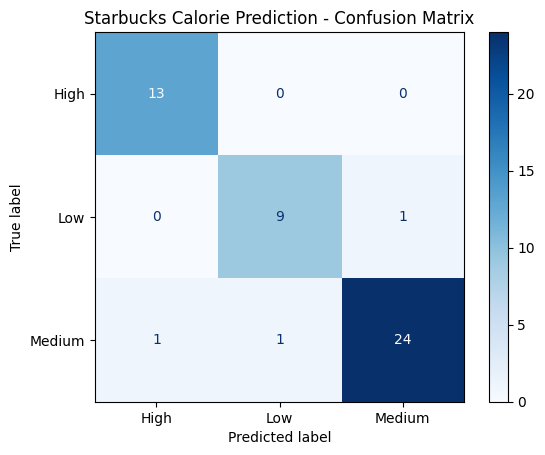

In [11]:

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_test_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=model.classes_
)

display.plot(cmap="Blues")
plt.title("Starbucks Calorie Prediction - Confusion Matrix")
plt.show()


In [16]:

# Recreate test predictions and show 10 results

X_test = X_test.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

predictions = model.predict(X_test)

print("10 SAMPLE PREDICTIONS")
print("======================")

for i in range(min(10, len(y_test))):
    print(
        "Actual:", y_test.iloc[i],
        "| Predicted:", predictions[i]
    )


10 SAMPLE PREDICTIONS
Actual: Medium | Predicted: Medium
Actual: High | Predicted: High
Actual: Medium | Predicted: High
Actual: Medium | Predicted: Medium
Actual: Medium | Predicted: Medium
Actual: Low | Predicted: Medium
Actual: Low | Predicted: Low
Actual: Medium | Predicted: Medium
Actual: High | Predicted: High
Actual: Low | Predicted: Low


In [17]:

import pickle

# Save the trained model
with open("starbucks_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Model saved successfully!")


Model saved successfully!


In [18]:

import json

metadata = {
    "feature_names": list(X_train.columns),
    "class_labels": [str(label) for label in model.classes_]
}

with open("starbucks_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Metadata saved successfully!")
print("Class labels:", metadata["class_labels"])


Metadata saved successfully!
Class labels: ['High', 'Low', 'Medium']


In [19]:

app_code = '''
import streamlit as st
import pandas as pd
import pickle
import json

st.set_page_config(page_title="Starbucks Nutrition Finder", page_icon="☕")

with open("starbucks_model.pkl", "rb") as f:
    model = pickle.load(f)

with open("starbucks_metadata.json", "r") as f:
    metadata = json.load(f)

st.title("Starbucks Nutrition Finder")
st.write("Predict the calorie category of your Starbucks drink.")

st.subheader("Enter Nutrition Information")

values = {}

for feature in metadata["feature_names"]:
    values[feature] = st.number_input(
        feature,
        min_value=0.0,
        value=0.0
    )

if st.button("Predict Calorie Category"):
    input_data = pd.DataFrame([values])
    prediction = model.predict(input_data)[0]

    st.success(f"Predicted Category: {prediction}")
'''

with open("app.py", "w") as file:
    file.write(app_code)

print("Streamlit app.py created successfully!")


Streamlit app.py created successfully!


In [20]:

requirements = """
streamlit
pandas
scikit-learn
"""

with open("requirements.txt", "w") as file:
    file.write(requirements.strip())

print("requirements.txt created successfully!")


requirements.txt created successfully!


In [21]:

readme = """
# Starbucks Nutrition Finder

## Project Description
A Machine Learning application that predicts
whether a Starbucks drink has Low, Medium,
or High calories.

## Technologies Used
- Python
- Pandas
- Scikit-learn
- Decision Tree Classifier
- Streamlit

## Model Accuracy
Validation Accuracy: 91%

## How to Run
1. Install requirements:
   pip install -r requirements.txt

2. Start the application:
   streamlit run app.py

## Project Goal
To help users understand the calorie category
of Starbucks beverages.
"""

with open("README.md", "w") as file:
    file.write(readme)

print("README.md created successfully!")


README.md created successfully!


In [22]:

import zipfile
import os

project_files = [
    "app.py",
    "starbucks_model.pkl",
    "starbucks_metadata.json",
    "requirements.txt",
    "README.md"
]

with zipfile.ZipFile("Starbucks_Nutrition_Finder.zip", "w") as zip_file:
    for file in project_files:
        if os.path.exists(file):
            zip_file.write(file)
        else:
            print("Missing file:", file)

print("Project ZIP created successfully!")
print("Files included:", project_files)


Project ZIP created successfully!
Files included: ['app.py', 'starbucks_model.pkl', 'starbucks_metadata.json', 'requirements.txt', 'README.md']
